# Modelo 2: Árbol de decisión — Telco Customer Churn (P2)

**Propósito:** entrenar, ajustar e interpretar un árbol de decisión para predecir `Churn`, siguiendo el protocolo definido en `P02_baseline_diseno_experimental.ipynb`.

**Qué se hace en este notebook:**

1. Se arma un `Pipeline` con el preprocesador compartido (`make_preprocessor("tree")` de `preprocessing.py`) y el clasificador.
2. Se evalúan 42 configuraciones (`max_depth`, `min_samples_leaf` y `class_weight`); cada una se entrena con **Train** y se mide en **Validation**.
3. Se elige la configuración con mayor **F1-score de `Churn=1` en Validation**, se analiza el sobreajuste y se interpreta el árbol (reglas, hojas e importancia de variables).

**Ejecución:** seguir las celdas en orden. Funciona desde la raíz del repositorio, desde `notebooks/` o en Google Colab (el repositorio se clona solo si hace falta). El código reutilizable está en la carpeta `src/`.

> **Importante:** este notebook **no usa Test**. Los tres modelos se evalúan una sola vez sobre Test en `P05_evaluacion_comparativa.ipynb`, cuando las configuraciones ya están cerradas.

## 1. Importación de librerías y localización del proyecto

In [1]:
import sys
import subprocess
import time
from pathlib import Path

# Se busca la raíz del repositorio en el directorio actual, en el directorio padre
# y en las ubicaciones habituales (misma lógica que en P02).
PROJECT_NAME = "Machine-Learning-Project"
REPO_URL = "https://github.com/sofkp/Machine-Learning-Project.git"

candidatos = [
    Path.cwd(),
    Path.cwd().parent,
    Path.cwd() / PROJECT_NAME,
    Path.cwd().parent / PROJECT_NAME,
    Path("/content") / PROJECT_NAME,
]


def es_raiz(ruta):
    return (ruta / "preprocessing.py").is_file() and (ruta / "src" / "protocolo.py").is_file()


ROOT = next((ruta.resolve() for ruta in candidatos if es_raiz(ruta)), None)

# En Colab, si el repositorio todavía no está en el entorno, se clona.
if ROOT is None and "google.colab" in sys.modules:
    destino = Path("/content") / PROJECT_NAME
    if not destino.exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(destino)], check=True)
    if es_raiz(destino):
        ROOT = destino.resolve()

if ROOT is None:
    raise FileNotFoundError(
        "No se encontró el repositorio (preprocessing.py y la carpeta src/). "
        "Clónalo y ejecuta este notebook desde su raíz o desde notebooks/."
    )

sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from src import analisis, graficos
from src.modelos import (
    GRILLA_ARBOL,
    PASO_MODELO,
    crear_arbol_decision,
    describir_arbol,
    desempate_arbol,
)
from src.protocolo import (
    METRICAS,
    NOMBRE_ARBOL,
    RESULTS_DIR,
    buscar_en_validacion,
    cargar_train_validation,
    evaluar_modelo,
    guardar_json,
    guardar_tabla,
    matriz_confusion,
    predecir,
    seleccionar_configuracion,
    tabla_metricas,
    versiones,
)

graficos.aplicar_estilo()
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 110)

print("Carpeta del proyecto:", ROOT.name)
print("Versiones:", versiones())

Carpeta del proyecto: Machine-Learning-Project
Versiones: {'python': '3.10.12', 'numpy': '2.2.6', 'pandas': '2.3.3', 'scikit-learn': '1.7.2'}


## 2. Datos y particiones

Mismas particiones estratificadas 60/20/20 de `split_data()` (semilla 42). `cargar_train_validation()` descarta Test dentro de la función, así que aquí solo existen Train y Validation.

In [2]:
X_train, X_val, y_train, y_val = cargar_train_validation()

print("Train:     ", X_train.shape, "| abandono:", round(y_train.mean(), 4))
print("Validation:", X_val.shape, "| abandono:", round(y_val.mean(), 4))

Train:      (4225, 19) | abandono: 0.2653
Validation: (1409, 19) | abandono: 0.2654


## 3. Modelo y pipeline

Un árbol de decisión (algoritmo CART de scikit-learn) divide a los clientes con preguntas sucesivas sobre una sola columna, por ejemplo `tenure ≤ 15.5` o "¿el contrato es `Month-to-month`?". En cada nodo elige la pregunta que más reduce la **impureza de Gini**, y cada hoja predice según la proporción de abandonos de los clientes de Train que llegan a ella. A diferencia de la regresión logística, puede representar relaciones no lineales e interacciones entre variables sin que haya que indicárselas.

**Preprocesamiento (dentro del `Pipeline`, ajustado solo con Train):** One-Hot Encoding de las 16 variables categóricas y reemplazo por 0 de los faltantes de `TotalCharges`. Las variables numéricas **no se escalan**, porque las particiones del árbol solo dependen del orden de los valores.

**El problema del sobreajuste.** Si se le deja crecer sin restricciones, el árbol sigue dividiendo hasta aislar casi cada cliente de Train, y esas reglas tan específicas no se cumplen en datos nuevos. Aquí se controla con **prepoda**:

| Hiperparámetro | Valores | Qué controla |
|---|---|---|
| `max_depth` | 2, 3, 4, 5, 6, 8, `None` | Cantidad máxima de preguntas encadenadas. `None` = sin límite. |
| `min_samples_leaf` | 1, 20, 50 | Mínimo de clientes de Train por hoja. Evita reglas apoyadas en muy pocos casos (20 ≈ 0.5 % de Train; 50 ≈ 1.2 %). |
| `class_weight` | `None`, `"balanced"` | Tratamiento del desbalance, igual que en la regresión logística. |

Son 7 × 3 × 2 = **42 configuraciones**, un presupuesto de búsqueda similar al de la regresión logística (36), también con tres hiperparámetros. No se usan SMOTE ni otros remuestreos, y el umbral queda fijo en 0,5.

**Detalles de implementación:** criterio de Gini y `random_state=42` (scikit-learn desempata al azar entre divisiones igual de buenas, así que la semilla hace reproducible el árbol). No se exploraron la poda por costo-complejidad (`ccp_alpha`), el criterio de entropía ni `min_samples_split`, para mantener una búsqueda comparable entre modelos.

In [3]:
ejemplo = crear_arbol_decision()
print("Pasos del Pipeline:")
for nombre, paso in ejemplo.steps:
    print(f" - {nombre}: {type(paso).__name__}")
print("\nClasificador:", ejemplo.named_steps[PASO_MODELO])

Pasos del Pipeline:
 - preprocesamiento: ColumnTransformer
 - modelo: DecisionTreeClassifier

Clasificador: DecisionTreeClassifier(random_state=42)


## 4. Grilla de hiperparámetros

La grilla se definió en `src/modelos.py` **antes** de ejecutar los experimentos. Su orden (`class_weight` → `max_depth` ascendente → `min_samples_leaf`) es el último criterio de desempate.

In [4]:
# None se muestra como texto para que la tabla sea legible.
grilla = pd.DataFrame([{k: ("None" if v is None else v) for k, v in cfg.items()} for cfg in GRILLA_ARBOL])
grilla.index = grilla.index + 1
grilla.index.name = "Configuración"
print("Configuraciones:", len(grilla))
for hiperparametro in grilla.columns:
    print(f" - {hiperparametro}: {pd.unique(grilla[hiperparametro]).tolist()}")
print("\nPrimeras y últimas configuraciones, en el orden de la grilla:")
display(pd.concat([grilla.head(3), grilla.tail(3)]))

Configuraciones: 42
 - class_weight: ['None', 'balanced']
 - max_depth: [2, 3, 4, 5, 6, 8, 'None']
 - min_samples_leaf: [1, 20, 50]

Primeras y últimas configuraciones, en el orden de la grilla:


,class_weight,max_depth,min_samples_leaf
Configuración,,,
1,None,2,1
2,None,2,20
3,None,2,50
40,balanced,None,1
41,balanced,None,20
42,balanced,None,50


## 5. Búsqueda con validación fija

Igual que en P03: un bucle explícito ajusta cada configuración **solo con Train** y calcula las cinco métricas en Train y en Validation. Además se registran la profundidad real y la cantidad de hojas de cada árbol.

In [5]:
inicio = time.time()
tabla = buscar_en_validacion(
    crear_arbol_decision, GRILLA_ARBOL, X_train, y_train, X_val, y_val, describir=describir_arbol
)
print(f"Búsqueda completada en {time.time() - inicio:.1f} s")
print("Configuraciones evaluadas:", len(tabla))

Búsqueda completada en 4.3 s
Configuraciones evaluadas: 42


In [6]:
columnas = [
    "Configuración", "class_weight", "max_depth", "min_samples_leaf",
    "F1-score (Train)", "F1-score (Validation)", "Precision (Validation)", "Recall (Validation)",
    "Accuracy (Validation)", "ROC-AUC (Validation)", "Profundidad real", "Hojas",
]
print("Resultados de las 42 configuraciones (la tabla completa, con todas las métricas, se exporta a CSV):")
display(tabla[columnas].round(4).set_index("Configuración"))

Resultados de las 42 configuraciones (la tabla completa, con todas las métricas, se exporta a CSV):


,class_weight,max_depth,min_samples_leaf,F1-score (Train),F1-score (Validation),Precision (Validation),Recall (Validation),Accuracy (Validation),ROC-AUC (Validation),Profundidad real,Hojas
Configuración,,,,,,,,,,,
1,None,2,1,0.5898,0.5792,0.5392,0.6257,0.7587,0.7798,2,4
2,None,2,20,0.5898,0.5792,0.5392,0.6257,0.7587,0.7798,2,4
3,None,2,50,0.5898,0.5792,0.5392,0.6257,0.7587,0.7798,2,4
4,None,3,1,0.5006,0.4797,0.7047,0.3636,0.7906,0.8083,3,8
5,None,3,20,0.5006,0.4797,0.7047,0.3636,0.7906,0.8083,3,8
6,None,3,50,0.5006,0.4797,0.7047,0.3636,0.7906,0.8083,3,8
7,None,4,1,0.5601,0.5397,0.6641,0.4545,0.7942,0.8192,4,16
8,None,4,20,0.5579,0.5405,0.6667,0.4545,0.7949,0.8225,4,16
9,None,4,50,0.5579,0.5405,0.6667,0.4545,0.7949,0.8225,4,16


## 6. Selección de la configuración

In [7]:
numero, parametros, empatadas = seleccionar_configuracion(tabla, GRILLA_ARBOL, desempate_arbol)

print("Configuración seleccionada:", numero)
print("Hiperparámetros:", parametros)
print("Configuraciones con el mismo F1 máximo:", empatadas)

print("\nLas ocho mejores configuraciones según F1-score en Validation:")
display(
    tabla.sort_values("F1-score (Validation)", ascending=False, kind="mergesort")
    .head(8)[columnas].round(4).set_index("Configuración")
)

Configuración seleccionada: 41
Hiperparámetros: {'class_weight': 'balanced', 'max_depth': None, 'min_samples_leaf': 20}
Configuraciones con el mismo F1 máximo: 1

Las ocho mejores configuraciones según F1-score en Validation:


,class_weight,max_depth,min_samples_leaf,F1-score (Train),F1-score (Validation),Precision (Validation),Recall (Validation),Accuracy (Validation),ROC-AUC (Validation),Profundidad real,Hojas
Configuración,,,,,,,,,,,
41,balanced,None,20,0.6852,0.6192,0.5305,0.7433,0.7573,0.8191,12,132
31,balanced,5,1,0.6487,0.6168,0.5087,0.7834,0.7417,0.8167,5,30
33,balanced,5,50,0.6467,0.6159,0.5096,0.7781,0.7424,0.8194,5,31
38,balanced,8,20,0.6756,0.6114,0.5117,0.7594,0.7438,0.8172,8,103
32,balanced,5,20,0.6436,0.6102,0.4934,0.7995,0.7289,0.8243,5,32
25,balanced,3,1,0.6256,0.6080,0.5000,0.7754,0.7346,0.8089,3,8
26,balanced,3,20,0.6256,0.6080,0.5000,0.7754,0.7346,0.8089,3,8
27,balanced,3,50,0.6256,0.6080,0.5000,0.7754,0.7346,0.8089,3,8


**Lectura.** La configuración elegida es la **41: `class_weight="balanced"`, `max_depth=None` y `min_samples_leaf=20`**, con F1 = 0.619 en Validation. No hubo empate. El árbol resultante tiene **12 niveles y 132 hojas**.

Tres observaciones para interpretar bien esta selección:

- `max_depth=None` es un extremo de la grilla, pero es el valor límite de ese hiperparámetro (no existe "más que sin límite"). Lo que realmente frena al árbol es `min_samples_leaf=20`, que está en el interior de su rango.
- La ventaja sobre las siguientes configuraciones es mínima. Un árbol de profundidad 5 con 30 hojas obtiene F1 = 0.617, y uno de profundidad 3 con solo 8 hojas, 0.608. En la sección 8 se comprueba que esas diferencias son menores que la incertidumbre del propio conjunto Validation.
- Se respeta la regla fijada de antemano (mayor F1 en Validation) y se mantiene la configuración 41, pero queda documentado que **un árbol mucho más pequeño rinde casi igual**.

## 7. Control del sobreajuste y tratamiento del desbalance

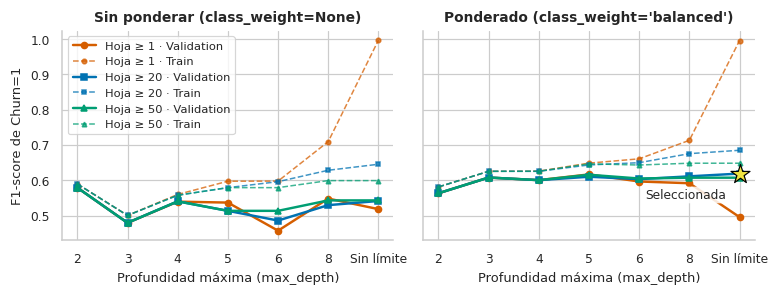

In [8]:
figura = graficos.figura_busqueda_arbol(tabla, numero)
graficos.guardar_figura(figura, "p04_busqueda_arbol_decision.png")
plt.show()

In [9]:
# Brecha Train-Validation según la complejidad (class_weight="balanced")
ponderados = tabla[tabla["class_weight"] == "balanced"].copy()
ponderados["Brecha de F1"] = ponderados["F1-score (Train)"] - ponderados["F1-score (Validation)"]
print("Con class_weight='balanced': tamaño del árbol y brecha Train-Validation")
display(
    ponderados[["max_depth", "min_samples_leaf", "Profundidad real", "Hojas", "F1-score (Train)",
                "F1-score (Validation)", "Brecha de F1", "ROC-AUC (Train)", "ROC-AUC (Validation)"]]
    .round(4).set_index(["max_depth", "min_samples_leaf"])
)

# Mejor configuración con y sin ponderación
mejores = (
    tabla.sort_values("F1-score (Validation)", ascending=False, kind="mergesort")
    .groupby("class_weight", sort=False).head(1)
)
print("Mejor configuración con y sin ponderación de clases:")
display(mejores[columnas].round(4).set_index("Configuración"))

sin_ponderar = tabla[tabla["class_weight"] == "None"]
print(
    "Sin ponderar: F1 en Validation entre",
    f"{sin_ponderar['F1-score (Validation)'].min():.3f} y {sin_ponderar['F1-score (Validation)'].max():.3f};",
    "Recall entre",
    f"{sin_ponderar['Recall (Validation)'].min():.3f} y {sin_ponderar['Recall (Validation)'].max():.3f}",
)
print(
    "Ponderado:    F1 en Validation entre",
    f"{ponderados['F1-score (Validation)'].min():.3f} y {ponderados['F1-score (Validation)'].max():.3f};",
    "Recall entre",
    f"{ponderados['Recall (Validation)'].min():.3f} y {ponderados['Recall (Validation)'].max():.3f}",
)

Con class_weight='balanced': tamaño del árbol y brecha Train-Validation


Profundidad real  Hojas  F1-score (Train)  \
max_depth min_samples_leaf                                              
2         1                                2      4            0.5814   
          20                               2      4            0.5814   
          50                               2      4            0.5814   
3         1                                3      8            0.6256   
          20                               3      8            0.6256   
          50                               3      8            0.6256   
4         1                                4     16            0.6261   
          20                               4     16            0.6257   
          50                               4     16            0.6257   
5         1                                5     30            0.6487   
          20                               5     32            0.6436   
          50                               5     31            0.6467   
6         1                                6     58            0.6610   
          20                               6     55            0.6500   
          50                               6     41            0.6434   
8         1                                8    169            0.7133   
          20                               8    103            0.6756   
          50                               8     54            0.6485   
None      1                               25    859            0.9960   
          20                              12    132            0.6852   
          50                              10     56            0.6485   

                            F1-score (Validation)  Brecha de F1  \
max_depth min_samples_leaf                                        
2         1                                0.5635        0.0179   
          20                               0.5635        0.0179   
          50                               0.5635        0.0179   
3         1                                0.6080        0.0176   
          20                               0.6080        0.0176   
          50                               0.6080        0.0176   
4         1                                0.6006        0.0255   
          20                               0.6006        0.0251   
          50                               0.6006        0.0251   
5         1                                0.6168        0.0319   
          20                               0.6102        0.0334   
          50                               0.6159        0.0309   
6         1                                0.5967        0.0642   
          20                               0.6034        0.0467   
          50                               0.6052        0.0382   
8         1                                0.5918        0.1215   
          20                               0.6114        0.0642   
          50                               0.6075        0.0410   
None      1                                0.4959        0.5001   
          20                               0.6192        0.0660   
          50                               0.6075        0.0410   

                            ROC-AUC (Train)  ROC-AUC (Validation)  
max_depth min_samples_leaf                                         
2         1                          0.7963                0.7798  
          20                         0.7963                0.7798  
          50                         0.7963                0.7798  
3         1                          0.8279                0.8089  
          20                         0.8279                0.8089  
          50                         0.8279                0.8089  
4         1                          0.8440                0.8199  
          20                         0.8435                0.8233  
          50                         0.8435                0.8233  
5         1                          0.8579               

Mejor configuración con y sin ponderación de clases:


,class_weight,max_depth,min_samples_leaf,F1-score (Train),F1-score (Validation),Precision (Validation),Recall (Validation),Accuracy (Validation),ROC-AUC (Validation),Profundidad real,Hojas
Configuración,,,,,,,,,,,
41,balanced,None,20,0.6852,0.6192,0.5305,0.7433,0.7573,0.8191,12,132
1,None,2,1,0.5898,0.5792,0.5392,0.6257,0.7587,0.7798,2,4


Sin ponderar: F1 en Validation entre 0.457 y 0.579; Recall entre 0.364 y 0.626
Ponderado:    F1 en Validation entre 0.496 y 0.619; Recall entre 0.487 y 0.866


**Sobreajuste.** El árbol sin restricciones (sin límite de profundidad y con hojas de un solo cliente) memoriza Train: con `class_weight="balanced"` llega a 859 hojas y 25 niveles, con F1 = 0.996 y ROC-AUC = 1.000 en Train, pero en Validation cae a F1 = 0.496 y ROC-AUC = 0.658. Es el peor árbol ponderado de toda la grilla, incluso por debajo de uno de solo dos niveles. Con hojas de un solo cliente, la brecha de F1 entre Train y Validation crece con la profundidad: está entre 0.02 y 0.03 hasta 5 niveles, y sube a 0.06 con 6, a 0.12 con 8 y a 0.50 sin límite. En la figura se ve como la separación entre la línea punteada (Train) y la continua (Validation).

**Efecto de `min_samples_leaf`.** Exigir al menos 20 clientes por hoja reduce el árbol sin límite de 859 a 132 hojas, y el F1 en Validation sube de 0.496 a 0.619 (ROC-AUC de 0.658 a 0.819). Con 50 clientes por hoja el árbol baja a 56 hojas y la brecha se reduce a 0.041, aunque el F1 es algo menor (0.608). En los árboles de hasta 4 niveles este hiperparámetro no cambia el F1, porque sus hojas ya son grandes.

**Desbalance.** Igual que en la regresión logística, ponderar las clases cambia el equilibrio entre Precision y Recall. Sin ponderar, los árboles detectan entre el 36 % y el 63 % de los abandonos y su F1 no pasa de 0.579; con `class_weight="balanced"` detectan entre el 74 % y el 87 % (dejando de lado el árbol sin restricciones) y el F1 llega a 0.619.

La razón se ve bien en un árbol: con `class_weight="balanced"`, una hoja predice abandono cuando su tasa de abandono en Train supera la tasa global (26.5 %), y no cuando supera el 50 %. Esto también explica la caída del F1 sin ponderar entre 2 y 3 niveles (panel izquierdo). Con 2 niveles, la única hoja que predice abandono es "contrato mensual con fibra óptica" (55.5 % de abandono). Con 3 niveles esa hoja se divide por antigüedad, y la mitad con más de 15 meses (41.7 %) deja de superar el 50 %: el Recall baja de 0.626 a 0.364 aunque el árbol sea más detallado.

**Sobre el ROC-AUC.** La configuración seleccionada no es la de mayor ROC-AUC en Validation (0.819, frente a 0.825 de los árboles con hojas de 50 clientes). El criterio acordado en P02 es el F1, así que se mantiene la selección, pero conviene saberlo al comparar modelos.

## 8. Modelo seleccionado: resultados en Validation

In [10]:
modelo = crear_arbol_decision(**parametros)
modelo.fit(X_train, y_train)  # preprocesador y clasificador se ajustan solo con Train

metricas_train = evaluar_modelo(modelo, X_train, y_train)
y_val_pred, y_val_proba = predecir(modelo, X_val)
metricas_val = evaluar_modelo(modelo, X_val, y_val)

# El modelo reajustado debe reproducir la fila correspondiente de la búsqueda.
fila = tabla.set_index("Configuración").loc[numero]
assert all(abs(metricas_val[m] - fila[f"{m} (Validation)"]) < 1e-12 for m in METRICAS)

tabla_seleccionado = tabla_metricas({NOMBRE_ARBOL: metricas_val}, "Validation")
matriz_val = matriz_confusion(y_val, y_val_pred)

baseline = pd.read_csv(RESULTS_DIR / "resultados_baseline_validacion.csv", encoding="utf-8-sig", index_col="Modelo")
print("Métricas en Validation (baseline de P02 y árbol de decisión seleccionado):")
display(pd.concat([baseline, tabla_seleccionado]).round(4))
print("Métricas del mismo modelo en Train (solo para ver la brecha):")
display(tabla_metricas({NOMBRE_ARBOL: metricas_train}, "Train").round(4))
print("Matriz de confusión en Validation (filas = clase real; columnas = predicción):")
display(matriz_val)

clasificador = modelo.named_steps[PASO_MODELO]
print(f"Tamaño del árbol: {clasificador.get_depth()} niveles y {clasificador.get_n_leaves()} hojas")

Métricas en Validation (baseline de P02 y árbol de decisión seleccionado):


,Conjunto,Accuracy,Precision,Recall,F1-score,ROC-AUC
Modelo,,,,,,
Dummy Classifier,Validation,0.7346,0.0000,0.0000,0.0000,0.5000
Árbol de decisión,Validation,0.7573,0.5305,0.7433,0.6192,0.8191


Métricas del mismo modelo en Train (solo para ver la brecha):


,Conjunto,Accuracy,Precision,Recall,F1-score,ROC-AUC
Modelo,,,,,,
Árbol de decisión,Train,0.8017,0.5918,0.8136,0.6852,0.8963


Matriz de confusión en Validation (filas = clase real; columnas = predicción):


,Predicho No (0),Predicho Sí (1)
Clase real,,
Real No (0),789,246
Real Sí (1),96,278


Tamaño del árbol: 12 niveles y 132 hojas


**Lectura.** En Validation el árbol detecta 278 de los 374 clientes que abandonaron (Recall = 0.743) y genera 246 falsas alarmas entre los 1035 que se quedaron (Precision = 0.531). Frente al Dummy, el F1 pasa de 0 a 0.619 y el ROC-AUC de 0.5 a 0.819.

La brecha entre Train (F1 = 0.685) y Validation (F1 = 0.619) es de 0.066: bastante mayor que la de la regresión logística (0.012). El árbol seleccionado todavía sobreajusta un poco, aunque muchísimo menos que el árbol sin restricciones.

**¿Es distinguible del árbol pequeño?** Para responderlo se compara el árbol seleccionado con el de 3 niveles y 8 hojas usando un bootstrap pareado sobre Validation (2000 remuestreos de los mismos clientes para ambos árboles).

In [11]:
arbol_pequeno = crear_arbol_decision(class_weight="balanced", max_depth=3, min_samples_leaf=20)
arbol_pequeno.fit(X_train, y_train)

_, diferencias = analisis.bootstrap_pareado(
    y_val,
    {
        "Árbol seleccionado (132 hojas)": (y_val_pred, y_val_proba),
        "Árbol de 3 niveles (8 hojas)": predecir(arbol_pequeno, X_val),
    },
    comparaciones=[("Árbol seleccionado (132 hojas)", "Árbol de 3 niveles (8 hojas)")],
)
print("Diferencia (árbol seleccionado − árbol de 3 niveles) en Validation,")
print("con intervalo bootstrap del 95 % (2000 remuestreos pareados):")
display(diferencias.round(3).set_index("Métrica").drop(columns="Comparación"))

Diferencia (árbol seleccionado − árbol de 3 niveles) en Validation,
con intervalo bootstrap del 95 % (2000 remuestreos pareados):


,Diferencia,IC inferior,IC superior,El IC excluye 0
Métrica,,,,
Accuracy,0.023,0.004,0.042,True
Precision,0.031,0.007,0.055,True
Recall,-0.032,-0.067,0.000,False
F1-score,0.011,-0.014,0.035,False
ROC-AUC,0.010,-0.008,0.028,False


**Lectura.** La diferencia de F1 es de +0.011, con un intervalo del 95 % de [−0.014, 0.035], y la de ROC-AUC es de +0.010 [−0.008, 0.028]. Los dos intervalos incluyen el cero: con este conjunto Validation **no se puede afirmar que el árbol de 132 hojas sea mejor que el de 8**. Y eso que la comparación favorece al árbol seleccionado, porque se eligió justamente por tener el mayor F1 en estos mismos datos.

Lo que sí cambia es el tipo de error. El árbol seleccionado es más preciso (+0.031 [0.007, 0.055]) y tiene mayor Accuracy (+0.023 [0.004, 0.042]), a cambio de un Recall algo menor (−0.032 [−0.067, 0.000]).

## 9. Interpretación del modelo

### 9.1 Primeros niveles del árbol

El árbol completo tiene 132 hojas, demasiadas para leerlas una por una. Sus primeros niveles, en cambio, concentran las divisiones más importantes. En el diagrama, cada caja muestra la pregunta, cuántos clientes de Train llegan a ese nodo y su **tasa real de abandono** (sin ponderar). La rama izquierda corresponde a "no" y la derecha a "sí".

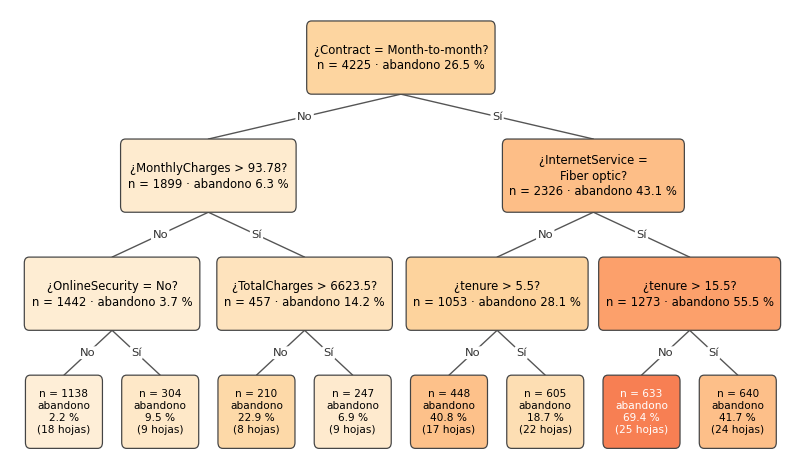

Raíz: n=4225, abandono=26.5 %
Si Contract ≠ Month-to-month  [n=1899, abandono=6.3 %]
|   Si MonthlyCharges ≤ 93.78  [n=1442, abandono=3.7 %]
|   |   Si OnlineSecurity ≠ No  [n=1138, abandono=2.2 %]
|   |   |   … subárbol omitido (n=1138, abandono=2.2 %)
|   |   Si OnlineSecurity = No  [n=304, abandono=9.5 %]
|   |   |   … subárbol omitido (n=304, abandono=9.5 %)
|   Si MonthlyCharges > 93.78  [n=457, abandono=14.2 %]
|   |   Si TotalCharges ≤ 6623.50  [n=210, abandono=22.9 %]
|   |   |   … subárbol omitido (n=210, abandono=22.9 %)
|   |   Si TotalCharges > 6623.50  [n=247, abandono=6.9 %]
|   |   |   … subárbol omitido (n=247, abandono=6.9 %)
Si Contract = Month-to-month  [n=2326, abandono=43.1 %]
|   Si InternetService ≠ Fiber optic  [n=1053, abandono=28.1 %]
|   |   Si tenure ≤ 5.50  [n=448, abandono=40.8 %]
|   |   |   … subárbol omitido (n=448, abandono=40.8 %)
|   |   Si tenure > 5.50  [n=605, abandono=18.7 %]
|   |   |   … subárbol omitido (n=605, abandono=18.7 %)
|   Si Internet

In [12]:
figura = graficos.figura_arbol(modelo, X_train, y_train, niveles=3)
graficos.guardar_figura(figura, "p04_arbol_decision_primeros_niveles.png")
plt.show()

print(analisis.reglas_arbol(modelo, X_train, y_train, profundidad_maxima=3))

**Lectura.** La primera pregunta es el tipo de contrato: los clientes con contrato mensual abandonan el 43.1 % de las veces y el resto, el 6.3 %. Dentro del contrato mensual, la siguiente pregunta es si tienen fibra óptica (55.5 % frente a 28.1 %), y después la antigüedad: los clientes con contrato mensual, fibra óptica y 15 meses o menos de antigüedad son el grupo de mayor riesgo, con **69.4 % de abandono** (633 clientes de Train). En los contratos de uno o dos años el árbol pregunta por el cargo mensual y luego por `OnlineSecurity` y `TotalCharges`, pero todas esas ramas tienen tasas bajas.

Lo valioso de este resultado es que el árbol encontró por sí solo la **interacción entre contrato, servicio de internet y antigüedad** que se había descrito en el análisis multivariable de P1. La regresión logística, en cambio, solo puede sumar el efecto de cada variable por separado.

### 9.2 Hojas: ¿las reglas se sostienen en Validation?

Cada hoja es una regla completa. La tabla compara, para cada una, la tasa de abandono en Train con la que se observa en Validation. `Probabilidad estimada` es la salida del modelo, que con `class_weight="balanced"` queda por encima de la tasa real de la hoja.

In [13]:
hojas = analisis.tabla_hojas(modelo, X_train, y_train, X_val, y_val)
alertas = hojas[hojas["Predicción"] == 1]
puras = hojas[hojas["Tasa de abandono (Train)"] == 0]

print("Hojas:", len(hojas), "| condiciones por regla: entre", hojas["Condiciones"].min(), "y", hojas["Condiciones"].max())
print(f"Hojas que predicen abandono: {len(alertas)} | clientes de Train en ellas: {alertas['Clientes (Train)'].sum()}",
      f"({100 * alertas['Clientes (Train)'].sum() / len(X_train):.1f} %)")
print("Tasa de abandono en Train de las hojas que predicen abandono: desde",
      f"{100 * alertas['Tasa de abandono (Train)'].min():.1f} % (tasa global: {100 * y_train.mean():.1f} %)")
print("Clientes de Train por hoja: mínimo", hojas["Clientes (Train)"].min(),
      "| mediana", int(hojas["Clientes (Train)"].median()), "| máximo", hojas["Clientes (Train)"].max())
print("Clientes de Validation por hoja: mínimo", hojas["Clientes (Validation)"].min(),
      "| mediana", int(hojas["Clientes (Validation)"].median()), "| máximo", hojas["Clientes (Validation)"].max())
print(f"Hojas con 0 % de abandono en Train: {len(puras)}, con {puras['Clientes (Train)'].sum()} clientes de Train.",
      f"En Validation: {puras['Abandonos (Validation)'].sum()} abandonos entre {puras['Clientes (Validation)'].sum()} clientes",
      f"({100 * puras['Abandonos (Validation)'].sum() / puras['Clientes (Validation)'].sum():.1f} %)")

print("\nHojas agrupadas por su tasa de abandono en Train:")
display(analisis.hojas_por_banda(hojas, y_train.mean()).round(3))


def mostrar_hojas(seleccion):
    for _, hoja in seleccion.iterrows():
        print(f" • {hoja['Regla']}")
        print(f"     Train: {hoja['Clientes (Train)']} clientes, {100 * hoja['Tasa de abandono (Train)']:.1f} % de abandono",
              f"| Validation: {hoja['Clientes (Validation)']} clientes, {100 * hoja['Tasa de abandono (Validation)']:.1f} %")


print("Las cuatro hojas con mayor riesgo estimado:")
mostrar_hojas(hojas.head(4))
print("\nLas cuatro hojas con más clientes de Train:")
mostrar_hojas(hojas.sort_values("Clientes (Train)", ascending=False, kind="mergesort").head(4))

Hojas: 132 | condiciones por regla: entre 5 y 12
Hojas que predicen abandono: 58 | clientes de Train en ellas: 1541 (36.5 %)
Tasa de abandono en Train de las hojas que predicen abandono: desde 27.0 % (tasa global: 26.5 %)
Clientes de Train por hoja: mínimo 20 | mediana 25 | máximo 244
Clientes de Validation por hoja: mínimo 2 | mediana 9 | máximo 93
Hojas con 0 % de abandono en Train: 20, con 1267 clientes de Train. En Validation: 13 abandonos entre 398 clientes (3.3 %)

Hojas agrupadas por su tasa de abandono en Train:


,Hojas,Predicen abandono,Clientes (Train),Tasa de abandono (Train),Clientes (Validation),Tasa de abandono (Validation)
Tasa de abandono de la hoja en Train,,,,,,
0–10 %,40,0,1783,0.020,579,0.060
10–26.5 %,34,0,901,0.192,306,0.199
26.5–50 %,22,22,618,0.380,202,0.396
50–75 %,20,20,540,0.626,198,0.545
75–100 %,16,16,383,0.885,124,0.726


Las cuatro hojas con mayor riesgo estimado:
 • Contract = Month-to-month y InternetService = Fiber optic y tenure ≤ 15.50 y 75.65 < TotalCharges ≤ 120.00 y MonthlyCharges ≤ 80.40
     Train: 25 clientes, 100.0 % de abandono | Validation: 6 clientes, 100.0 %
 • Contract = Month-to-month y InternetService = Fiber optic y tenure ≤ 15.50 y TotalCharges ≤ 75.65 y MonthlyCharges ≤ 69.92
     Train: 23 clientes, 100.0 % de abandono | Validation: 9 clientes, 100.0 %
 • Contract = Month-to-month y InternetService = Fiber optic y tenure ≤ 7.50 y TotalCharges > 120.00 y 82.95 < MonthlyCharges ≤ 89.55 y OnlineSecurity ≠ Yes y MultipleLines ≠ No y PaperlessBilling ≠ No
     Train: 21 clientes, 100.0 % de abandono | Validation: 4 clientes, 75.0 %
 • Contract = Month-to-month y InternetService = Fiber optic y 7.50 < tenure ≤ 15.50 y TotalCharges > 120.00 y MonthlyCharges > 80.40 y OnlineSecurity ≠ Yes y MultipleLines ≠ No y PaperlessBilling ≠ No y SeniorCitizen = 1
     Train: 22 clientes, 95.5 % de 

**Lectura.** De las 132 hojas, 58 predicen abandono y reúnen a 1541 clientes de Train (36.5 %). Como se explicó en la sección 7, son las hojas cuya tasa de abandono en Train supera la tasa global.

Cada hoja recibe muy pocos clientes de Validation (mediana de 9), así que comparar hoja por hoja sería puro ruido. Agrupadas por nivel de riesgo, se ven dos cosas:

- **El orden se sostiene.** Las hojas que en Train tenían más abandono también lo tienen en Validation, y en las bandas intermedias las tasas casi coinciden (19.2 % frente a 19.9 %, y 38.0 % frente a 39.6 %).
- **Los extremos se moderan.** Las hojas con más de 75 % de abandono en Train (88.5 % en conjunto) bajan a 72.6 % en Validation, y las 20 hojas que en Train no tenían ningún abandono muestran 3.3 % en Validation (13 de 398 clientes). Es el sobreajuste que queda: las hojas pequeñas exageran lo que vieron en Train.

Las hojas de mayor riesgo son todas variantes del mismo perfil (contrato mensual, fibra óptica y hasta 15 meses de antigüedad), y las más grandes describen clientes con contrato de uno o dos años que no pagan con cheque electrónico. Las reglas completas tienen entre 5 y 12 condiciones, así que el árbol entero **no** se puede leer como un conjunto corto de reglas; lo interpretable son sus primeros niveles.

### 9.3 Importancia de las variables

Se comparan dos medidas:

- **MDI (reducción de impureza):** cuánto contribuye cada variable a reducir la impureza de Gini en Train. Se suma por variable original. Tiende a favorecer a las variables numéricas, que ofrecen muchos puntos de corte.
- **Permutación en Validation:** cuánto cae el F1 al desordenar la variable (30 repeticiones), igual que en P03.

In [14]:
mdi_por_columna, mdi_por_variable = analisis.importancias_arbol(modelo)
permutacion = analisis.importancia_por_permutacion(modelo, X_val, y_val, n_repeticiones=30)

comparacion_importancias = mdi_por_variable.merge(permutacion, on="Variable")
display(comparacion_importancias.round(4))
print("Variables que el árbol no usa en ninguna división:",
      list(mdi_por_variable.loc[mdi_por_variable["Divisiones que la usan"] == 0, "Variable"]) or "ninguna")

,Variable,Importancia (MDI),Divisiones que la usan,Caída de F1-score (media),Caída de F1-score (DE),Caída de ROC-AUC (media),Caída de ROC-AUC (DE)
0,Contract,0.5137,3,0.1804,0.0156,0.0888,0.0097
1,tenure,0.0982,13,0.1160,0.0144,0.0733,0.0078
2,MonthlyCharges,0.0858,38,0.0014,0.0054,0.0258,0.0051
3,InternetService,0.0848,1,0.1379,0.0134,0.0935,0.0098
4,TotalCharges,0.0731,26,0.0567,0.0097,0.0266,0.0050
5,OnlineSecurity,0.0228,4,0.0191,0.0069,0.0195,0.0037
6,PaymentMethod,0.0213,9,0.0028,0.0034,0.0035,0.0029
7,TechSupport,0.0199,4,0.0161,0.0039,0.0078,0.0026
8,PhoneService,0.0139,2,-0.0002,0.0018,-0.0016,0.0015
9,gender,0.0124,8,0.0035,0.0032,0.0084,0.0023


Variables que el árbol no usa en ninguna división: ninguna


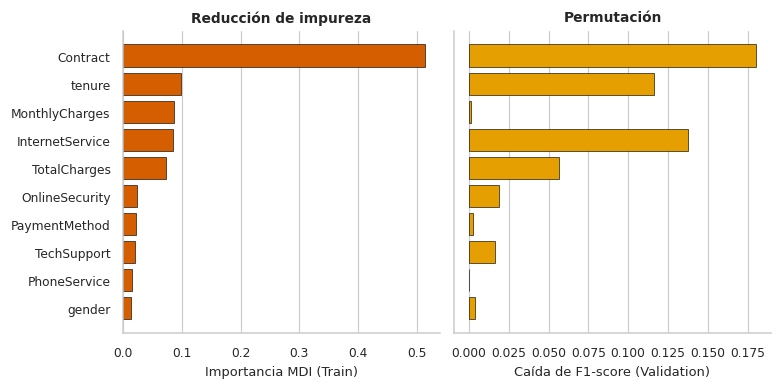

In [15]:
figura = graficos.figura_importancias_arbol(mdi_por_variable, permutacion, cantidad=10)
graficos.guardar_figura(figura, "p04_importancias_arbol_decision.png")
plt.show()

**Lectura.** Las dos medidas coinciden en la variable principal: `Contract` concentra el 51 % de la reducción de impureza, y al permutarla el F1 cae 0.180. Según la permutación le siguen `InternetService` (0.138), `tenure` (0.116) y `TotalCharges` (0.057); el resto queda por debajo de 0.02.

Donde no coinciden es justamente donde se nota el sesgo de la MDI:

- `MonthlyCharges` es la variable más usada (38 de las 131 divisiones) y la tercera según la MDI, pero al permutarla el F1 casi no cambia (0.001), aunque el ROC-AUC sí baja (0.026). Sus divisiones ajustan las probabilidades dentro de cada rama, pero casi nunca cambian qué clientes superan el umbral de 0,5.
- `InternetService` aparece en **una sola** división (la segunda del árbol) y aun así es la segunda variable más importante por permutación.
- Las tres variables numéricas suman 77 de las 131 divisiones. El árbol llega a usar las 19 variables, incluida `gender` (8 divisiones), que en el EDA no mostraba relación con el abandono y cuya importancia por permutación es indistinguible de cero (0.003 ± 0.003). Son divisiones profundas que probablemente ajustan ruido de Train.

Como en la regresión logística, estas importancias describen **en qué se apoya el modelo**, no qué causa el abandono.

## 10. Exportar resultados

In [16]:
ruta_reglas = RESULTS_DIR / "reglas_arbol_decision.txt"
ruta_reglas.write_text(analisis.reglas_arbol(modelo, X_train, y_train) + "\n", encoding="utf-8")

rutas = [
    guardar_tabla(tabla, "resultados_arbol_decision_grilla_validacion.csv", index=False),
    guardar_tabla(tabla_seleccionado, "resultados_arbol_decision_validacion.csv"),
    guardar_tabla(matriz_val, "matriz_confusion_arbol_decision_validacion.csv"),
    guardar_tabla(comparacion_importancias, "importancias_arbol_decision.csv", index=False),
    guardar_tabla(permutacion, "importancia_permutacion_arbol_decision_validacion.csv", index=False),
    guardar_tabla(hojas, "hojas_arbol_decision.csv", index=False),
    ruta_reglas,
    guardar_json(
        {
            "modelo": NOMBRE_ARBOL,
            "configuracion": numero,
            "hiperparametros": parametros,
            "criterio": "Mayor F1-score de Churn=1 en Validation (protocolo de P02)",
            "configuraciones_evaluadas": len(tabla),
            "configuraciones_empatadas": empatadas,
            "profundidad_real": int(clasificador.get_depth()),
            "hojas": int(clasificador.get_n_leaves()),
            "metricas_train": metricas_train,
            "metricas_validation": metricas_val,
            "versiones": versiones(),
        },
        "configuracion_arbol_decision.json",
    ),
]
print("Archivos creados en resultados/:")
for ruta in rutas:
    print(" -", ruta.name)
print("Figuras en resultados/figuras/: p04_busqueda_arbol_decision.png, "
      "p04_arbol_decision_primeros_niveles.png, p04_importancias_arbol_decision.png")

Archivos creados en resultados/:
 - resultados_arbol_decision_grilla_validacion.csv
 - resultados_arbol_decision_validacion.csv
 - matriz_confusion_arbol_decision_validacion.csv
 - importancias_arbol_decision.csv
 - importancia_permutacion_arbol_decision_validacion.csv
 - hojas_arbol_decision.csv
 - reglas_arbol_decision.txt
 - configuracion_arbol_decision.json
Figuras en resultados/figuras/: p04_busqueda_arbol_decision.png, p04_arbol_decision_primeros_niveles.png, p04_importancias_arbol_decision.png


## 11. Conclusiones de esta parte

- **Configuración seleccionada:** árbol con `class_weight="balanced"`, sin límite de profundidad y con al menos 20 clientes por hoja (12 niveles, 132 hojas). En Validation: F1 = 0.619, Precision = 0.531, Recall = 0.743, Accuracy = 0.757 y ROC-AUC = 0.819.
- **Sobreajuste:** sin restricciones, el árbol memoriza Train (F1 = 0.996) y cae a 0.496 en Validation. `min_samples_leaf` lo controla, aunque el árbol elegido conserva una brecha de 0.066, mayor que la de la regresión logística (0.012).
- **Desbalance:** la ponderación de clases sube el F1 del mejor árbol de 0.579 a 0.619, porque mueve el criterio de alerta de "más de 50 % de abandono en la hoja" a "más que la tasa global".
- **Interpretación:** el árbol descubre solo la interacción contrato × internet × antigüedad vista en P1. El grupo de mayor riesgo (contrato mensual, fibra óptica y hasta 15 meses de antigüedad) tiene 69.4 % de abandono en Train.
- **Advertencia:** la ventaja del árbol elegido sobre uno de 8 hojas (+0.011 de F1) queda dentro de la incertidumbre de Validation. Si se priorizara la interpretabilidad, el árbol de 3 niveles sería una alternativa razonable; aquí se mantiene el criterio definido antes de experimentar.

La configuración queda guardada en `resultados/configuracion_arbol_decision.json`. La comparación con la regresión logística y la evaluación en Test están en `P05_evaluacion_comparativa.ipynb`.